# Prediction of BS incoming in 90 s

In [2]:
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from Prediction.extract_data import *
import json
import matplotlib.pyplot as plt


import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.model_selection import StratifiedKFold
import pandas as pd
import shap

## Extract the variables 

### Load dictionnary for BS data

In [2]:
with open('Prediction/Dictionnary.json', 'r') as json_file:
    D_BS = json.load(json_file)

### Load for OK data

In [3]:
with open('Prediction/Ok_data.json', 'r') as file:
    D_OK = json.load(file)

### Extract data

In [4]:
# 1 label: IES in less than 90 s
var1 = get_label_1_data(D_BS, prior_t = 90, delta_t = 240)
# 0 label: no IES in less than 90 s
var0 = get_label_0_data(D_OK, delta_t = 240)

rec_20240321_085300.mat
rec_20240125_094414.mat


c:\Users\pmich\Desktop\data prediction\Spindles\get_spindle_type.py:205: RuntimeWarning: divide by zero encountered in scalar divide
  ratio = np.sum(mask_slow) / np.sum(mask_fast)


rec_20240321_131557.mat
rec_20240411_122350.mat
rec_20240411_103638.mat
rec_20240411_090403.mat
eeg_producer__10_10_2024__10_44_13.npy
eeg_producer__17_10_2024__09_04_07.npy
d_AA68
no ground check detected


C:\Users\pmich\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pywt\_multilevel.py:43: UserWarning: Level value of 4 is too high: all coefficients will experience boundary effects.
  warnings.warn(


d_AB56
no ground check detected
d_AW67
no ground check detected
d_BE74
no ground check detected
d_BN49
d_BN65
no ground check detected
d_CC65
no ground check detected
d_CV71
d_EA68
d_FA68
no ground check detected
d_LC82
no ground check detected
d_LM67
no ground check detected
d_LP46
no ground check detected
d_MC50
no ground check detected
d_MG73
no ground check detected
d_MJ49
no ground check detected
d_NR49
no ground check detected
d_OA40
no ground check detected
d_OA44
d_PC52
d_PM63
no ground check detected
d_RR63
no ground check detected
d_SD63
no ground check detected
d_SG74
no ground check detected
d_SR74
no ground check detected
d_TC58
no ground check detected
d_TN66
no ground check detected
d_YS66
no ground check detected
rec_20240411_090403
rec_20230629_092502
rec_20240328_104241
rec_20240328_104241
rec_20240328_104241
rec_20240328_104241
rec_20230713_143459
rec_20231207_094352
rec_20231207_094352
rec_20231207_094352
rec_20240111_090304


C:\Users\pmich\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\io\matlab\_mio.py:227: MatReadWarning: Duplicate variable name "None" in stream - replacing previous with new
Consider mio5.varmats_from_mat to split file into single variable files
  matfile_dict = MR.get_variables(variable_names)


rec_20240111_090304
rec_20240111_115315
rec_20240111_115315
rec_20240118_115349
rec_20240118_115349
rec_20240125_110611
rec_20240125_110611
rec_20240125_115738
rec_20240201_110448
rec_20240201_110448
rec_20240201_110448
rec_20240208_105055
rec_20240208_105055
rec_20240208_105055
rec_20240208_105055
rec_20240208_105055
rec_20240215_105447
rec_20240215_105447
rec_20240215_115539
rec_20240215_115539
rec_20240229_090001
rec_20240307_092703
rec_20240314_090226
rec_20240314_090226
rec_20240314_090226
rec_20240314_090226
rec_20240321_085300
rec_20240321_131557


## get variables for the classifier

In [2]:
# list for selected samples for label 1
L_BS = [35,33,29,27,25,23,21,19,18,17,15,12,11,8,7,5,4,3,2,1]

Run if not already saved

Extract trend and value at origin

In [ ]:
res0=[]
res1=[]

for i in L_BS:

    a1=np.zeros((10,2))

    N=len(var1[i-1][0])
    t1=np.linspace(0,N*5,N)

    for k in range(10):

        popt=np.polyfit(t1,var1[i-1][k],1)
        a1[k,0]=popt[0]
        a1[k,1]=popt[1]
    
    res1.append(a1)

for i in range(len(var0)):

    a0=np.zeros((10,2))

    N=len(var0[i][0])
    t0=np.linspace(0,N*5,N)

    for k in range(10):

        popt=np.polyfit(t0,var0[i][k],1)
        a0[k,0]=popt[0]
        a0[k,1]=popt[1]
    
    res0.append(a0)

res1=np.array(res1)
res0=np.array(res0)

# save data for faster reloading
np.save('res1.npy', res1)
np.save('res0.npy', res0)

Run if already saved res1 and res0


In [3]:
res1 = np.load('res1.npy')
res0 = np.load('res0.npy')

### Visualize distributions

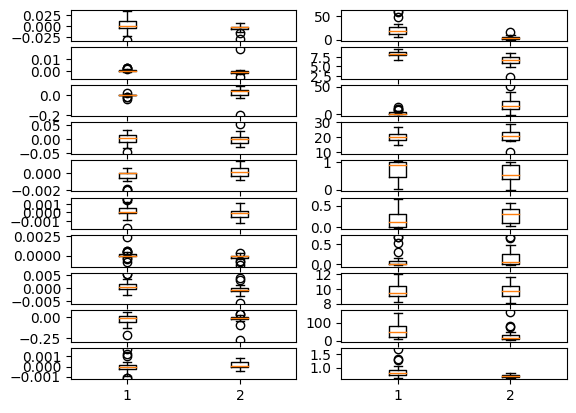

In [4]:
fig,axes = plt.subplots(10, 2)
for k in range(10):
    L = [res0[:,k,0], res1[:,k,0]]
    axes[k,0].boxplot(L)
    L = [res0[:,k,1], res1[:,k,1]]
    axes[k,1].boxplot(L)

plt.show()

In [6]:
print(res0)

[[[ 1.26373493e-02  9.30438483e+00]
  [ 9.01926987e-04  7.87218700e+00]
  [-1.85572377e-02  1.37560931e+01]
  [ 5.19459875e-03  2.20225530e+01]
  [-5.61808170e-04  1.16591796e-01]
  [ 4.05488254e-06  2.25258362e-01]
  [ 5.57753287e-04  6.58149842e-01]
  [ 4.46094090e-04  1.20186845e+01]
  [-4.43668573e-02  1.14745025e+02]
  [-8.17039685e-05  6.88768353e-01]]

 [[ 6.18231126e-03  1.57090607e+01]
  [ 4.06336074e-04  8.10999077e+00]
  [-2.87335359e-03  9.60323446e-01]
  [-1.27445161e-02  2.15375332e+01]
  [ 1.37863786e-04  7.20687161e-01]
  [-4.40106517e-05  2.62507930e-01]
  [-9.38531338e-05  1.68049089e-02]
  [ 1.33723725e-03  1.02647978e+01]
  [ 6.27168001e-02  6.48192589e+01]
  [ 4.83335670e-05  9.00657756e-01]]

 [[-2.18789593e-03  1.42697565e+01]
  [-1.93133467e-04  7.86200735e+00]
  [ 3.31054963e-03 -9.18400749e-02]
  [ 1.33981608e-02  1.71862004e+01]
  [-5.11083979e-04  3.36047697e-01]
  [ 6.08092663e-04  5.55158994e-01]
  [-9.70086842e-05  1.08793309e-01]
  [ 2.85494176e-04  1.07

In [7]:
print(res1)

[[[-7.58478965e-04  1.36610836e+00]
  [-1.87712003e-04  5.93183175e+00]
  [ 5.59796777e-02  2.14951412e+01]
  [-5.67950763e-03  2.20573699e+01]
  [-3.48587011e-04  9.76556339e-01]
  [ 3.48587011e-04  2.34436607e-02]
  [ 0.00000000e+00  0.00000000e+00]
  [ 1.06243468e-03  8.75883667e+00]
  [-1.01691508e-02  6.54281186e+00]
  [ 1.67358158e-04  6.29026458e-01]]

 [[-5.59402600e-03  4.38901940e+00]
  [-8.20799413e-04  7.46429651e+00]
  [ 6.18066390e-02  1.42500785e+01]
  [-1.25110775e-02  1.73856118e+01]
  [ 1.41937142e-03  1.18909334e-01]
  [-9.59049912e-04  5.52409604e-01]
  [-4.60321503e-04  3.28681062e-01]
  [-2.82008165e-03  1.08840475e+01]
  [-7.58788951e-03  8.07802106e+00]
  [ 5.29980350e-04  6.99347317e-01]]

 [[-2.76040537e-03  2.28736155e+00]
  [-1.47488401e-03  6.77555446e+00]
  [ 4.33516772e-03  2.92456730e+01]
  [-1.98678156e-02  2.52938646e+01]
  [ 6.31951725e-04  6.89250804e-01]
  [-4.98090440e-04  2.42092164e-01]
  [-1.33861285e-04  6.86570320e-02]
  [-8.94470633e-04  9.54

Run to take only delta parameters (to delete to have full parameters)

In [11]:
# res0 = res0[:,-2:,:]
# res1 = res1[:,-2:,:]

In [12]:
# print(res0)

In [13]:
# print(res1)

# Train classifier

Set data into correct format

In [6]:
X = []
for res in res0:
    X.append(np.reshape(res,20))

for res in res1:
    X.append(np.reshape(res,20))

y = np.array([0]*len(res0) + [1]*len(L_BS)) 

Train without k-fold

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[LightGBM] [Info] Number of positive: 14, number of negative: 27
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000041 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 194
[LightGBM] [Info] Number of data points in the train set: 41, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.341463 -> initscore=-0.656780
[LightGBM] [Info] Start training from score -0.656780
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [War

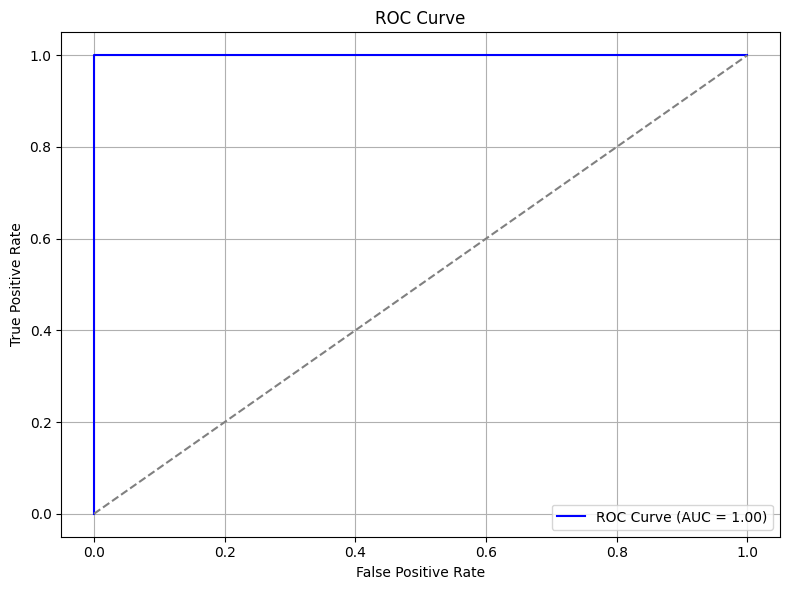

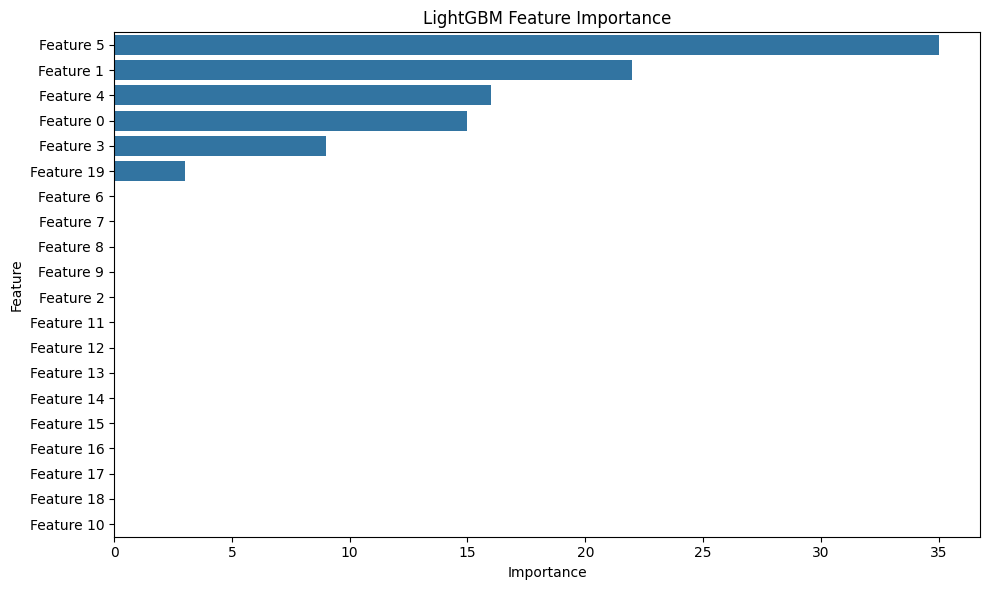

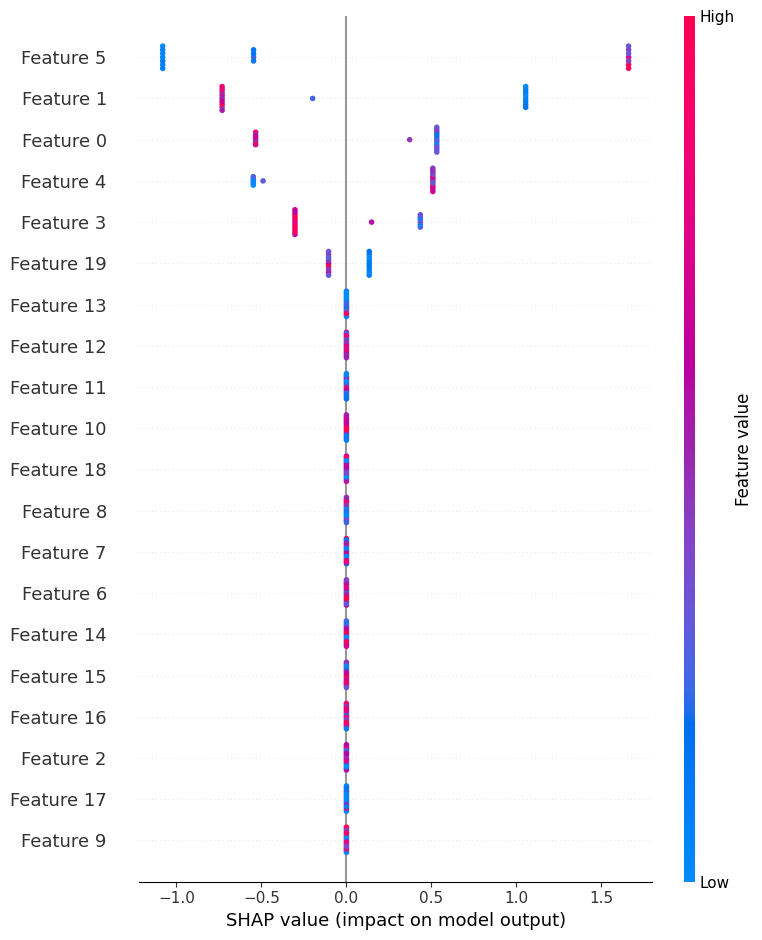

In [7]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import GridSearchCV, train_test_split
import pandas as pd
import shap

# Splitting dataset into training and testing sets
X = np.array(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

# Define the LightGBM classifier
lgbm_clf = lgb.LGBMClassifier(random_state=42)

# Define the hyperparameter grid for GridSearchCV
param_grid = {
    'num_leaves': [31, 50, 70],
    'max_depth': [5, 10, 15],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 200]
}

# Set up GridSearchCV with stratified cross-validation
grid_search = GridSearchCV(estimator=lgbm_clf, param_grid=param_grid, 
                           cv=5, scoring='accuracy', n_jobs=-1, verbose=1)

# Train the model using GridSearchCV
grid_search.fit(X_train, y_train)

# Output the best hyperparameters found by GridSearchCV
print("Best hyperparameters:", grid_search.best_params_)

# Predict on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]  # For ROC AUC

# Classification metrics
print("Classification Report:\n", classification_report(y_test, y_pred))

# Compute and print ROC AUC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Plot Feature Importance
feature_importance = best_model.feature_importances_

# Handle NumPy array by creating generic feature names
feature_names = [f"Feature {i}" for i in range(X.shape[1])]
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('LightGBM Feature Importance')
plt.tight_layout()
plt.show()

# Ensure X_test is a NumPy array and use the same feature names
X_test_array = np.array(X_test)

# Create SHAP explainer and compute SHAP values
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test_array)

# SHAP summary plot
shap.summary_plot(shap_values, X_test_array, feature_names=feature_names)


Train with stratified Kfold

Fitting 5 folds for each of 54 candidates, totalling 270 fits
[LightGBM] [Info] Number of positive: 14, number of negative: 27
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000718 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 194
[LightGBM] [Info] Number of data points in the train set: 41, number of used features: 13
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.341463 -> initscore=-0.656780
[LightGBM] [Info] Start training from score -0.656780
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[Lig

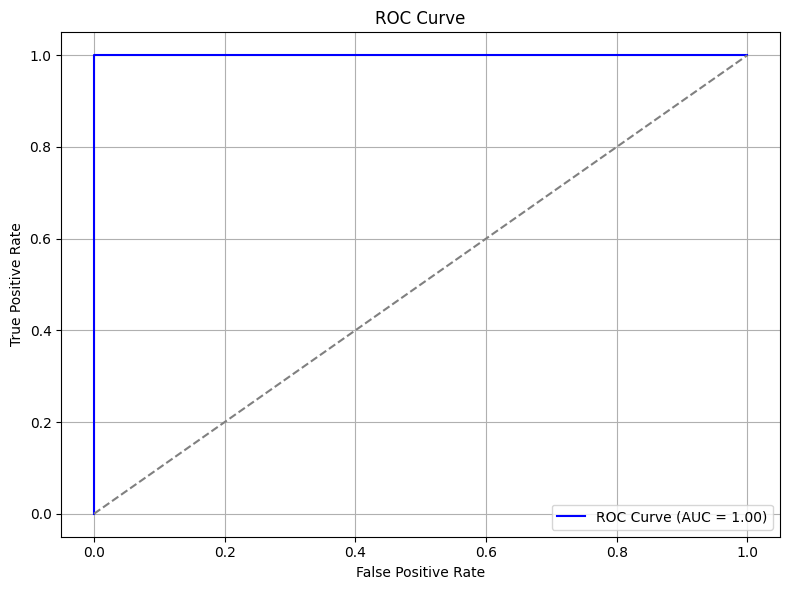

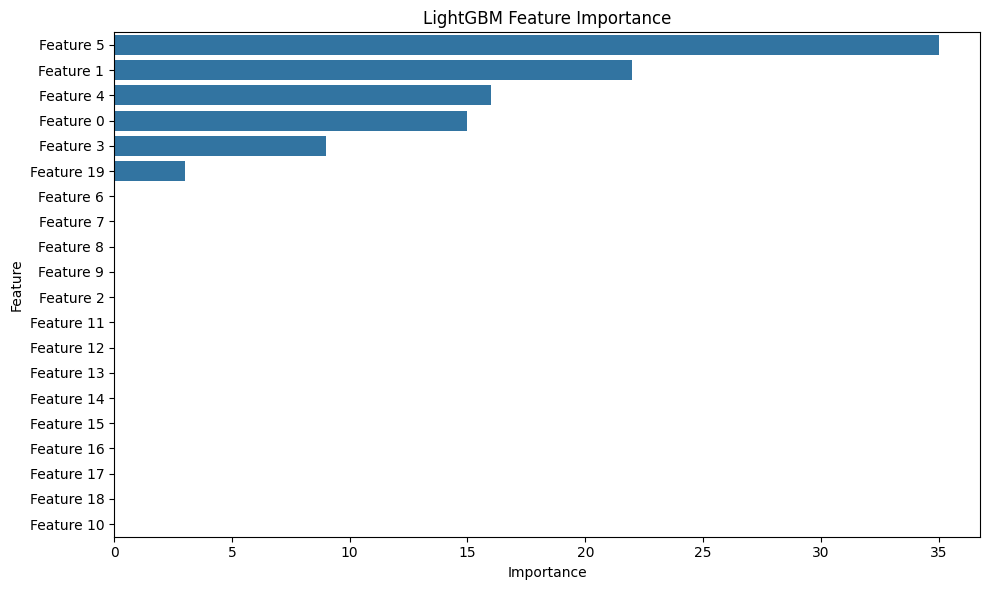

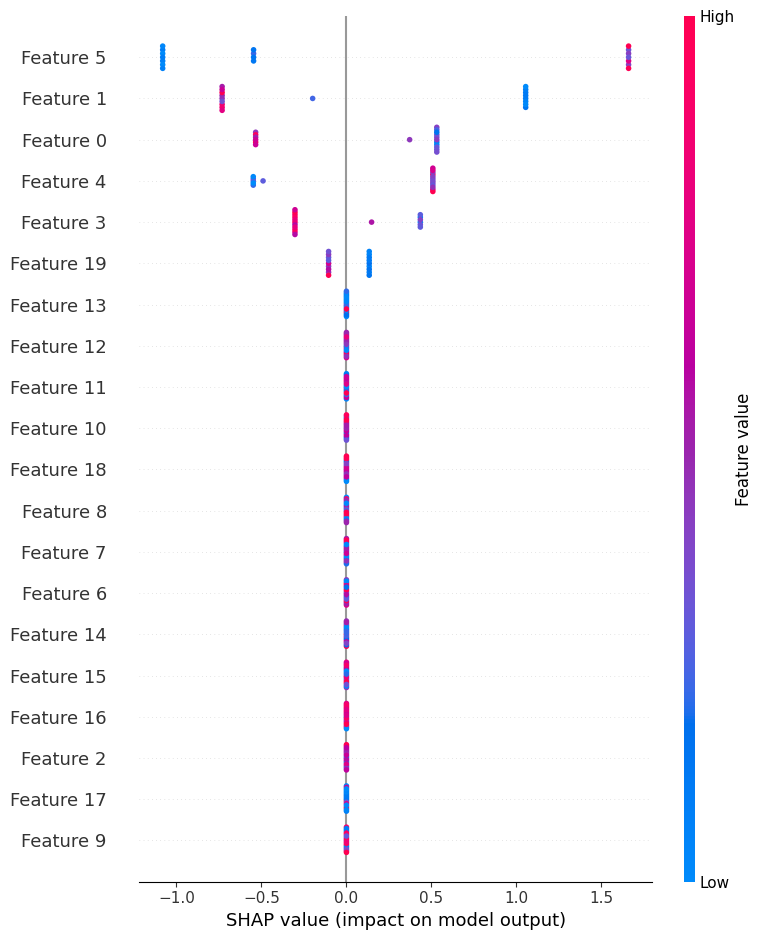

In [8]:
# Splitting dataset into training and testing sets
X = np.array(X)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.3, random_state=42)

# Define the LightGBM classifier
lgbm_clf = lgb.LGBMClassifier(random_state=42)

# Define the hyperparameter grid for GridSearchCV
param_grid = {
    'num_leaves': [31, 50, 70],
    'max_depth': [5, 10, 15],
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 200]
}

# Define Stratified K-Fold
stratified_kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Use Stratified CV in GridSearch
grid_search = GridSearchCV(estimator=lgbm_clf,
                           param_grid=param_grid, 
                           cv=stratified_kfold,  # <- stratified split
                           scoring='accuracy', 
                           n_jobs=-1, 
                           verbose=1)

# Train the model using GridSearchCV
grid_search.fit(X_train, y_train)

# Output the best hyperparameters found by GridSearchCV
print("Best hyperparameters:", grid_search.best_params_)

# Predict on the test set
best_model = grid_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]  # For ROC AUC

# Classification metrics
print("Classification Report:\n", classification_report(y_test, y_pred))

# Compute and print ROC AUC
roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC AUC Score: {roc_auc:.4f}")

# Plot ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc:.2f})', color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

# Plot Feature Importance
feature_importance = best_model.feature_importances_

# Handle NumPy array by creating generic feature names
feature_names = [f"Feature {i}" for i in range(X.shape[1])]
importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importance})
importance_df = importance_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('LightGBM Feature Importance')
plt.tight_layout()
plt.show()

# Ensure X_test is a NumPy array and use the same feature names
X_test_array = np.array(X_test)

# Create SHAP explainer and compute SHAP values
explainer = shap.Explainer(best_model)
shap_values = explainer(X_test_array)

# SHAP summary plot
shap.summary_plot(shap_values, X_test_array, feature_names=feature_names)


In [11]:
import joblib
# save model
# Save full grid search object (including best_model, scores, etc.)
joblib.dump(grid_search, 'lgbm_grid_search.pkl')

NameError: name 'grid_search' is not defined

# load data for mice

In [9]:
with open('Prediction/Dictionnary_mice.json', 'r') as file:
    D_mice = json.load(file)

In [10]:
# samples leading to IES for mice
var_mice = get_graded_anesthesia_data(D_mice, prior_t = 90, delta_t = 240)

LFP_22-12-20_15-08-10.npy
LFP_22-12-21_13-09-10.npy
LFP_23-03-16_12-16-07.npy
LFP_24-11-08_15-07-06.npy
LFP_24-11-15_16-35-53.npy
LFP_24-11-18_17-28-29.npy
LFP_24-12-13_13-24-59.npy
LFP_25-07-03_13-48-54.npy
LFP_25-07-04_10-33-00.npy
LFP_25-07-05_12-45-01.npy


In [14]:
print(var_mice)

[array([[1.60617838e+03, 1.61035224e+03, 1.61689536e+03, 1.62460003e+03,
        1.62994412e+03, 1.63398662e+03, 1.63508285e+03, 1.63573314e+03,
        1.64035715e+03, 1.64340016e+03, 1.64377139e+03, 1.64224382e+03,
        1.64233953e+03, 1.64258810e+03, 1.64435251e+03, 1.64735950e+03,
        1.64935509e+03, 1.65250560e+03, 1.65597508e+03, 1.65956811e+03,
        1.66351261e+03, 1.66829148e+03, 1.67538555e+03, 1.68084325e+03,
        1.68402169e+03, 1.68855853e+03, 1.69264745e+03, 1.69937191e+03,
        1.70753435e+03, 1.71407650e+03, 1.71636598e+03, 1.72094494e+03,
        1.72552390e+03, 1.73010286e+03, 1.73468182e+03, 1.73926078e+03,
        1.74383974e+03, 1.74841870e+03, 1.75299766e+03, 1.75757662e+03,
        1.76215558e+03, 1.76673454e+03, 1.77131350e+03, 1.77589246e+03,
        1.78047142e+03, 1.78505038e+03, 1.78962934e+03, 1.79420829e+03],
       [1.32317697e+01, 1.32331002e+01, 1.32355246e+01, 1.32382991e+01,
        1.32400404e+01, 1.32406710e+01, 1.32400782e+01, 1.3239

In [12]:
res_mice=[]


for i in range(len(var_mice)):

    a0 = np.zeros((10,2))

    N = len(var_mice[i][0])
    t0 = np.linspace(0,N*5,N)

    for k in range(10):

        popt=np.polyfit(t0,var_mice[i][k],1)
        a0[k,0]=popt[0]
        a0[k,1]=popt[1]
    
    res_mice.append(a0)

res_mice=np.array(res_mice)

# save data for faster reloading
np.save('res_mice.npy', res_mice)

In [15]:
print(res_mice)

[[[ 7.73470958e-01  1.59939183e+03]
  [ 1.49893994e-04  1.32307443e+01]
  [-5.67597865e-03  2.82319023e+00]
  [-7.37913684e-03  1.84155287e+01]
  [ 4.67597941e-04  6.67611372e-01]
  [-3.14546261e-04  3.03184195e-01]
  [-1.53051681e-04  2.92044335e-02]
  [ 2.39457037e-06  7.51040505e+00]
  [ 2.02744114e+01  2.11885607e+04]
  [ 4.24052389e-05  6.52156386e-01]]

 [[ 2.73588710e+00  3.53115343e+03]
  [ 4.46331023e-04  1.37569865e+01]
  [ 5.45989348e-03  5.25361031e-01]
  [ 4.21173928e-02  1.60390627e+01]
  [ 4.12507930e-04  4.06583972e-01]
  [-6.75340873e-04  6.01779654e-01]
  [ 2.62832944e-04 -8.36362598e-03]
  [ 2.62432108e-03  7.46967503e+00]
  [-2.82328353e+01  4.37063871e+04]
  [-5.48741541e-04  8.66979086e-01]]

 [[ 2.24395601e+00  2.08476805e+03]
  [ 6.64527874e-04  1.34022265e+01]
  [-4.26001421e-04  1.17227425e+00]
  [-1.25874636e-02  2.12867192e+01]
  [-6.18956764e-04  7.83076683e-01]
  [ 8.56489280e-04  1.67624817e-01]
  [-2.37532515e-04  4.92985001e-02]
  [-6.81373398e-04  7.59

In [ ]:
res_mice = np.load('res_mice.npy')

## Visualize distributions

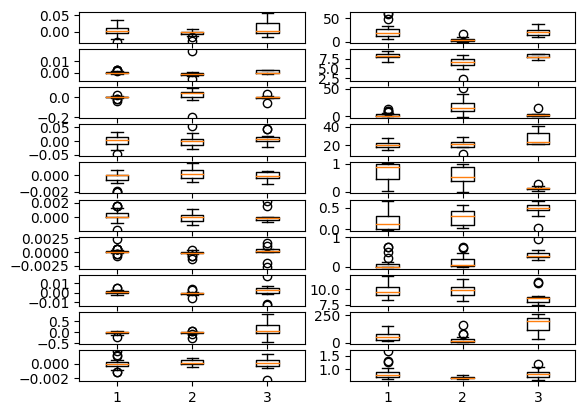

In [13]:
fig,axes = plt.subplots(10, 2)
for k in range(10):
    L = [res0[:,k,0], res1[:,k,0], res_mice[:,k,0]]
    axes[k,0].boxplot(L)
    L = [res0[:,k,1], res1[:,k,1], res_mice[:,k,1]]
    axes[k,1].boxplot(L)

plt.show()

## Load the model

In [14]:
import joblib

In [15]:
# Load it back
grid_search_loaded = joblib.load('lgbm_grid_search.pkl')

# Access the best model directly
model = grid_search_loaded.best_estimator_

## See outputs on mice data

In [1]:
X_mice = []
for res in res_mice:
    X_mice.append(np.reshape(res,20))

NameError: name 'res_mice' is not defined

In [17]:
y_pred_mice = model.predict(X_mice)
print(y_pred_mice)

[0 0 0 0 0 0 0 0 0 0]


In [18]:
y_proba_new = model.predict_proba(X_mice)[:, 1]

print(y_proba_new)

[0.03074196 0.02314307 0.14482235 0.05091115 0.29200153 0.32089265
 0.02632547 0.01686341 0.03872215 0.01081022]
